In [1]:
from abc import ABCMeta, abstractmethod
from ai import MAB
import pickle
import gzip
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import japanize_matplotlib

class MAB_Agent(metaclass=ABCMeta):
    def __init__(self, p):
        self.mab = MAB(p=p)
        self.title = self.NAME
        
    def save(self, fname):
        with gzip.open(f"{fname}.pkl", "wb") as f:
            pickle.dump(self, f)
            print("save completed.")        
        
    @staticmethod
    def load(fname):
        with gzip.open(f"{fname}.pkl", "rb") as f:
            return pickle.load(f)   

    def play_episode(self, stepnum):
        self.stepnum = stepnum
        self.total_coin = 0
        self.total_coins = []
        self.mean_coin = 0
        self.mean_coins = []
        self.slot = {
            "total_coin": [0] * self.mab.num,
            "mean_coin": [0] * self.mab.num,
            "selectnum": [0] * self.mab.num,
            "total_coins": [[] for _ in range(self.mab.num)],
            "mean_coins": [[] for _ in range(self.mab.num)],
            "selectnums": [[] for _ in range(self.mab.num)],
        }

        for self.step in range(self.stepnum):
            selectarm = self.select_arm()
            coin = self.mab.play(selectarm)
            self.total_coin += coin
            self.total_coins.append(self.total_coin)
            self.mean_coin = self.total_coin / (self.step + 1)
            self.mean_coins.append(self.mean_coin)
            self.slot["total_coin"][selectarm] += coin
            self.slot["selectnum"][selectarm] += 1
            self.slot["mean_coin"][selectarm] = self.slot["total_coin"][selectarm] / self.slot["selectnum"][selectarm]
            for arm in range(self.mab.num):
                self.slot["total_coins"][arm].append(self.slot["total_coin"][arm])
                self.slot["mean_coins"][arm].append(self.slot["mean_coin"][arm])
                self.slot["selectnums"][arm].append(self.slot["selectnum"][arm])
            
    @abstractmethod    
    def select_arm(self):
        pass  
    
    def play_episodes(self, stepnum, episodenum):
        self.stepnum = stepnum
        self.episodenum = episodenum
        self.mean_coins_by_step = np.zeros((self.episodenum, self.stepnum))
        self.slotratio_by_step = np.zeros((self.mab.num, self.episodenum, self.stepnum))

        for episode in tqdm(range(self.episodenum)):  
            self.play_episode(self.stepnum)
            self.mean_coins_by_step[episode, :] = self.mean_coins
            for arm in range(self.mab.num):
                self.slotratio_by_step[arm, episode, :] = self.slot["mean_coins"][arm]            
    
        self.mean_mean_coins_by_step = np.mean(self.mean_coins_by_step, axis=0)
        self.std_mean_coins_by_step = np.std(self.mean_coins_by_step, axis=0)
        self.mean_estimate_coins_by_step = np.mean(self.slotratio_by_step , axis=1) 
        self.std_estimate_coins_by_step = np.std(self.slotratio_by_step , axis=1)    
        
    def print_summary(self):
        print(f"{self.title} の結果のまとめ")
        if hasattr(self, "stepnum"):
            print("============================")
            print(f"総ステップ数 = {self.stepnum}")
            print("最後に行われたエピソードの結果")
            print(f"得られたコインの総数　 = {self.total_coin:5d}")
            print(f"得られたコインの平均　 = {self.mean_coin:.3f}")
            for arm in range(self.mab.num):
                print(f"スロットマシン {arm} (p={self.mab.p[arm]:.2f})")
                print(f"  得られたコインの総数 = {self.slot["total_coin"][arm]:5d}")
                print(f"  レバーを引いた回数　 = {self.slot["selectnum"][arm]:5d}")
                print(f"  得られたコインの平均 = {self.slot["mean_coin"][arm]:.3f}")            
        if hasattr(self, "episodenum"):
            print("============================")
            print(f"{self.episodenum} エピソードの結果")
            print(f"最終ステップのステップ当たりのコインの平均　　 = {self.mean_mean_coins_by_step[-1]:.3f}")            
            print(f"最終ステップのステップ当たりのコインの標準偏差 = {self.std_mean_coins_by_step[-1]:.3f}")
            for arm in range(self.mab.num):
                print(f"スロットマシン {arm} (p={self.mab.p[arm]:.2f})")
                print(f"  最終ステップの当たりの確率の推測値の平均　　 = {self.mean_estimate_coins_by_step[arm][-1]:.3f}")
                print(f"  最終ステップの当たりの確率の推測値の標準偏差 = {self.std_estimate_coins_by_step[arm][-1]:.5f}")
        print()
                
    def draw_cumulative_reward(self):
        plt.title(f"{self.title}\n累積報酬")
        maxp = max(self.mab.p)
        upperbounds = [step * maxp for step in range(self.stepnum)]
        plt.plot(upperbounds, label="上限", c="k")
        plt.plot(self.total_coins, label="コインの総数")
        for arm in range(self.mab.num):
            plt.plot(self.slot["total_coins"][arm], linestyle="--",
                     label=f"arm {arm} (p={self.mab.p[arm]:.2f})")
        plt.xlabel("ステップ数")
        plt.ylabel("コインの枚数")
        plt.legend()
        plt.show() 

    def draw_cumulative_reward_per_step(self):
        plt.title(f"{self.title}\nステップ当たりの累積報酬")
        maxp = max(self.mab.p)
        upperbounds = [maxp for step in range(self.stepnum)]
        plt.plot(upperbounds, label="上限", c="k")        
        mean = np.mean(self.mab.p)
        means = [mean for step in range(self.stepnum)]
        plt.plot(means, label="当たりの平均")
        plt.plot(self.mean_coins, label="ステップ当たりのコインの枚数")
        plt.ylim(0, 1)
        plt.xlabel("ステップ数")
        plt.ylabel("ステップ当たりのコインの枚数")
        plt.legend()
        plt.show() 
        
    def draw_selectnum(self):
        plt.title(f"{self.title}\nスロットマシンの選択回数")
        for arm in range(self.mab.num):
            plt.plot(self.slot["selectnums"][arm], label=f"arm {arm} (p={self.mab.p[arm]:.2f})")
        plt.xlabel("ステップ数")
        plt.ylabel("選択回数")
        plt.legend()
        plt.show()

    def draw_estimated_odds_of_arm(self):
        plt.title(f"{self.title}\nスロットマシンの当たりの確率の推定値")
        for arm in range(self.mab.num):
            plt.plot([self.mab.p[arm] for _ in range(self.stepnum)], linestyle=":", c="k")
            plt.plot(self.slot["mean_coins"][arm], label=f"arm {arm} (p={self.mab.p[arm]:.2f})")
        plt.ylim(0, 1)
        plt.xlabel("ステップ数")
        plt.ylabel("当たりの確率")
        plt.legend()
        plt.show()
        
    def draw_cumulative_rewards(self, episodenum=10):
        plt.title(f"{self.title}\n{episodenum} エピソードのステップ当たりの累積報酬")        
        for episode in range(episodenum):  
            plt.plot(self.mean_coins_by_step[episode, :])
        plt.xlabel("ステップ数")
        plt.ylabel("ステップ当たりのコインの枚数")
        plt.show()
        
    def draw_mean_cumulative_reward_by_step(self):
        plt.title(f"{self.title}\nステップ当たりの累積報酬の平均（{self.episodenum} エピソード）")
        plt.plot(self.mean_mean_coins_by_step)
        plt.xlabel("ステップ数")
        plt.ylabel("ステップ当たりの累積報酬の平均")
        plt.show()
        
    @staticmethod
    def compare_mean_cumulative_reward_by_step(agent_list):
        plt.title(f"ステップ当たりの累積報酬の平均の比較（{agent_list[0].episodenum} エピソード）")
        maxp = max(agent_list[0].mab.p)
        upperbounds = [maxp for step in range(agent_list[0].stepnum)]
        plt.plot(upperbounds, label="上限", c="k")
        for agent in agent_list:
            plt.plot(agent.mean_mean_coins_by_step, label=agent.title)
        plt.xlabel("ステップ数")
        plt.ylabel("ステップ当たりの累積報酬の平均")
        plt.ylim(0, 1)
        plt.legend()
        plt.show() 
        
    def draw_std_cumulative_reward_by_step(self):
        plt.title(f"{self.title}\nステップ当たりの累積報酬の標準偏差（{self.episodenum} エピソード）")
        plt.plot(self.std_mean_coins_by_step)
        plt.xlabel("ステップ数")
        plt.ylabel("ステップ当たりの累積報酬の標準偏差")
        plt.ylim(0, 1)
        plt.show()
        
    @staticmethod
    def compare_std_cumulative_reward_by_step(agent_list):
        plt.title(f"ステップ当たりの累積報酬の標準偏差の比較（{agent_list[0].episodenum} エピソード）")
        for agent in agent_list:
            plt.plot(agent.std_mean_coins_by_step, label=agent.title)
        plt.xlabel("ステップ数")
        plt.ylabel("ステップ当たりの累積報酬の標準偏差")
        plt.ylim(0, 1)
        plt.legend()
        plt.show()  
        
    def draw_histogram_of_cumulative_reward_by_step(self, steplist=None, stepmul=10):
        if steplist is None:
            steplist = []
            step = 1
            while step < self.stepnum:
                steplist.append(step - 1)
                step *= stepmul
            steplist.append(self.stepnum - 1)
        for step in steplist:
            plt.title(f"{self.title}\n{step} ステップでのステップ当たりの累積報酬（{self.episodenum} エピソード）")
            plt.hist(self.mean_coins_by_step[:, step], bins=20)
            plt.xlabel("ステップ当たりの累積報酬")
            plt.ylabel("回数")
            plt.show()      
            
    def draw_ci_of_cumulative_reward_by_step(self, sigmul=3):
        plt.title(f"{self.title}\nステップ当たりの累積報酬の平均 ± {sigmul}σ の範囲（{self.episodenum} エピソード）")
        plt.plot(self.mean_mean_coins_by_step)
        mean_minus_sigma = self.mean_mean_coins_by_step - sigmul * self.std_mean_coins_by_step
        mean_plus_sigma = self.mean_mean_coins_by_step + sigmul * self.std_mean_coins_by_step
        plt.fill_between(np.arange(self.stepnum), mean_minus_sigma, mean_plus_sigma, alpha=0.5)
        plt.ylim(0, 1)
        plt.xlabel("ステップ数")
        plt.ylabel("ステップ当たりの累積報酬の平均")
        plt.show() 

    def draw_ci_of_estimated_odds_of_arm(self, sigmul=3):        
        plt.title(f"{self.title}\nスロットマシンの当たりの確率の推測値の平均 ± {sigmul}σ の範囲（{self.episodenum} エピソード）")
        for arm in range(self.mab.num):
            plt.plot(self.mean_estimate_coins_by_step[arm], label=f"arm {arm} (p={self.mab.p[arm]:.2f})")
            mean_minus_sigma = self.mean_estimate_coins_by_step[arm] - sigmul * self.std_estimate_coins_by_step[arm]
            mean_plus_sigma = self.mean_estimate_coins_by_step[arm] + sigmul * self.std_estimate_coins_by_step[arm]
            plt.fill_between(np.arange(self.stepnum), mean_minus_sigma, mean_plus_sigma, alpha=0.5)
        plt.ylim(0, 1)
        plt.xlabel("ステップ数")
        plt.ylabel("当たりの確率")
        plt.legend()
        plt.show()
        
    def draw_std_estimated_odds_of_arm(self):        
        std = np.std(self.slotratio_by_step , axis=1)
        plt.title(f"{self.title}\nスロットマシンの当たりの確率の推測値の標準偏差（{self.episodenum} エピソード）")
        for arm in range(self.mab.num):
            plt.plot(std[arm], label=f"arm {arm} (p={self.mab.p[arm]:.2f})")
        plt.xlabel("ステップ数")
        plt.ylabel("標準偏差")
        plt.ylim(0, 1)
        plt.legend()
        plt.show()  

In [ ]:
class Random_MAB_Agent(MAB_Agent):
    NAME = "完全ランダム（原始モンテカルロ法の近似）"
    
    def select_arm(self):
        return np.random.choice(self.mab.num)

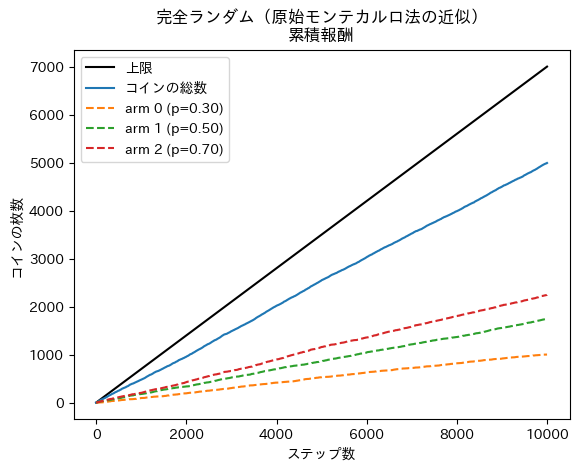

完全ランダム（原始モンテカルロ法の近似） の結果のまとめ
総ステップ数 = 10000
最後に行われたエピソードの結果
得られたコインの総数　 =  4991
得られたコインの平均　 = 0.499
スロットマシン 0 (p=0.30)
  得られたコインの総数 =  1001
  レバーを引いた回数　 =  3337
  得られたコインの平均 = 0.300
スロットマシン 1 (p=0.50)
  得られたコインの総数 =  1747
  レバーを引いた回数　 =  3428
  得られたコインの平均 = 0.510
スロットマシン 2 (p=0.70)
  得られたコインの総数 =  2243
  レバーを引いた回数　 =  3235
  得られたコインの平均 = 0.693



In [ ]:
p = [0.3, 0.5, 0.7]
random_agent = Random_MAB_Agent(p=p)
random_agent.play_episode(stepnum=10000)
random_agent.draw_cumulative_reward()
random_agent.print_summary()